In [1]:
import os
import glob
import pandas as pd
import rasterio
import numpy as np

In [ ]:
def preparer_donnees_climat_rapide():
   
    
    df_grille = pd.read_csv("Data\csv_final\grid_portugal_1km.csv")

    print(f"Grille: {len(df_grille)} points")
    
    
    df_complet = df_grille[['longitude', 'latitude']].copy()
    tif_path = r"Data\Rar\be15_grd"   
    valeurs = extraction_vectorisee(tif_path, df_grille)
    df_complet["Elevation"] = valeurs
            
    valides = np.sum(~np.isnan(valeurs))
    print(f"({valides} valides)")
    
   
    output_csv = os.path.join("Data", "Elevation\donnees_elevation_1km.csv")
    df_complet.to_csv(output_csv, index=False)
    
    return df_complet


def extraction_vectorisee(tif_path, df_points):
    with rasterio.open(tif_path) as src:
        
        rows, cols = rasterio.transform.rowcol(
            src.transform, 
            df_points['longitude'].values, 
            df_points['latitude'].values
        )
        
       
        mask = (rows >= 0) & (rows < src.height) & (cols >= 0) & (cols < src.width)
        
 
        valeurs = np.full(len(df_points), np.nan)
        
        if np.any(mask):
         
            data = src.read(1)
            valeurs_valides = data[rows[mask], cols[mask]]
            
     
            valeurs[mask] = valeurs_valides
            
         
            valeurs[valeurs == src.nodata] = np.nan
    
    return valeurs


donnees_rapides = preparer_donnees_climat_rapide()

Grille: 89198 points
(89198 valides)


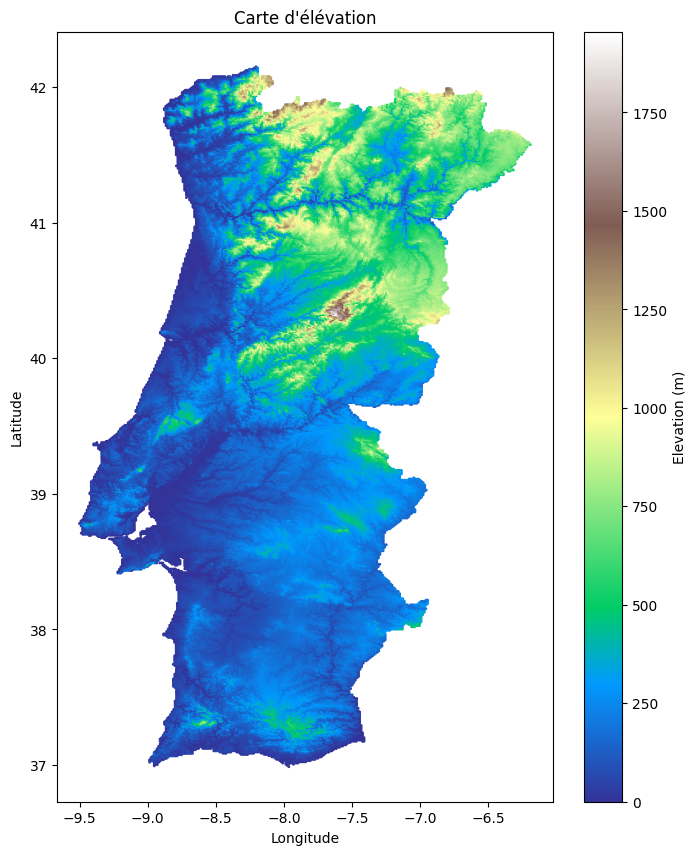

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 10))
plt.scatter(
    donnees_rapides["longitude"],
    donnees_rapides["latitude"],
    c=donnees_rapides["Elevation"],
    s=1,
    cmap="terrain"
)
plt.colorbar(label="Elevation (m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Carte d'élévation")
plt.show()